# Example calculation of the Young's modulus
This is a simplified adaptation from the RFR example scripts.
Please refer to their examples for more details, as well more properties the RFR method can extract.

All credits to them for this code, I just removed the parts I didn't need for this exact example:
- RFR_stress_strain project: https://github.com/CMMRLab/RFR_stress_strain/tree/main
- Publication: Kemppainen, J., Muzzy, T., Wavrunek, T.K. et al. Automatic determination of mechanical properties from Molecular Dynamic Stress-Strain curves using Regression Fringe Response. Commun Eng 5, 103 (2026). https://doi-org.proxy.bnl.lu/10.1038/s44172-026-00669-6

I wanted to provide this script to show how the Young's modulus was calculated in the specific case of our publication, which is essentially this in a wrapper function for convenience.
However, to compute your own values, you should probably use their examples/templates and not this one.

## Import RFR modules (and others)
RFR is not packaged by default, but it's fairly straightforward to do so and then `pip install .`
Otherwise put this script in the `RFR_stress_strain` directory or add the `RFR_stress_strain` directory to `PATH`

In [1]:
import modules.read_log as read_log
import modules.signals as signals
import modules.rfr as rfr

import matplotlib.pyplot as plt
import numpy as np

## Inputs and parameters

In [2]:
# logfile reading settings
logfile = "../../data/young/afd_young.log.lammps" # logfile to read
keywords = ['Step'] # used to find thermo sections in the logfile
sections = 1 # sections of the logfile to read. Our's only has 1 section

# columns of the logfile to use. Since we only have x strain in this case, we can use these
# Check the RFR examples on how to automatically set those for other directions
stress_column = 'f_sxx_ave'  # Axial stress
strain_column = 'v_etruex'   # Axial strain

# Regression fringe response settings
minxhi = 0.025 # mininum strain region to use for the linear fit
maxxhi = 0.000 # maximum strain region to use for the linear fit. Using 0 disables it

# Filter settings
order = 2 # order of the Butterworth lowpass filter
wn = 'op' # critical frequency. Using op optimizes it automatically
quadrant_mirror = 'msr' # quadrant mirroring. Using msr calculates it automatically

## Read the logfile

In [3]:
# read log
log = read_log.file(logfile, keywords=keywords, pflag=False)
data = log.get_data(sections, remove_duplicates=True, pflag=False)

# obtain strain and stress
stress = np.array(data[stress_column])
strain = np.array(data[strain_column])

## Filter the data

In [4]:
# Compute the PSD if wn is set to 'op'
if str(wn).startswith('op'):
    # Compute the PSD for different data sets
    wns_stress, psd_stress = signals.compute_PSD(strain, stress)

    # Find the mean value of the different PSD's
    mean_stress_psd = np.mean(psd_stress)

    # Find where each PSD crosses the mean
    wn_stress = wns_stress[np.min(np.where(psd_stress < mean_stress_psd)[0])]
    print('{:<50} {}'.format('Computed normalized cutoff frequency for stress: ', wn_stress))

    # Compute the corresponding power value for the crossing of the mean
    power_stress = psd_stress[np.min(np.where(wns_stress == wn_stress)[0])]

    # Filter the data with an optimized wn value
    filtered_stress, qm_stress = signals.butter_lowpass_filter(strain, stress, wn_stress, order, quadrant_mirror)

else:
    # Filter the data with a user defined wn value
    filtered_stress, qm_stress = signals.butter_lowpass_filter(strain, stress, wn, order, quadrant_mirror)

# Shift all data by the "minimum before the maximum" to remove any residual
# stress. The "minimum before the maximum" allows for fracture to occur where
# the minimum stress is near zero strain and not maximum strain (in case fracture
# creates a minimum stress lower then the residual stress).
max_index = np.min(np.where(filtered_stress == np.max(filtered_stress))[0])
min_stress = np.min(filtered_stress[:max_index])
filtered_stress -= min_stress
stress -= min_stress

Computed normalized cutoff frequency for stress:   0.0034662045060658577


## Compute the fringe response

In [5]:
# Step1: First forward response (fr1 - applying minxhi and maxxhi accordingly)
min_strain_fr1 = min(strain); max_strain_fr1 = max(strain)
if minxhi > 0: min_strain_fr1 = minxhi
if maxxhi > 0: max_strain_fr1 = maxxhi
fr1_fringe, fr1_slopes = rfr.compute_fringe_slope(strain, filtered_stress, min_strain=min_strain_fr1, max_strain=max_strain_fr1, direction='forward')
fr1_max_index = np.argmax(fr1_slopes)
fr1_max_slope = fr1_slopes[fr1_max_index]
fr1_max_fringe = fr1_fringe[fr1_max_index]

# Step2: First backwards response (br1 - applying minxhi and maxxhi accordingly)
min_strain_br1 = min(strain)
max_strain_br1 = fr1_max_fringe - minxhi # use minxhi to set the "span" of the smallest linear region acceptable
fr1_max_index_absolute = np.argmin(np.abs(strain - fr1_max_fringe))
reduced_strain = strain[0:fr1_max_index_absolute]
reduced_stress = filtered_stress[0:fr1_max_index_absolute]

br1_fringe, br1_slopes = rfr.compute_fringe_slope(reduced_strain, reduced_stress, min_strain=min_strain_br1, max_strain=max_strain_br1, direction='reverse')
br1_max_index = np.argmax(br1_slopes)
br1_max_slope = br1_slopes[br1_max_index]
br1_max_fringe = br1_fringe[br1_max_index]
br1_max_index_absolute = np.argmin(np.abs(strain - br1_max_fringe))

# Step3: Second forward response (fr2 - applying minxhi and maxxhi accordingly)
min_strain_fr2 = min_strain_fr1 + br1_max_fringe
max_strain_fr2 = max_strain_fr1 + br1_max_fringe
reduced_strain = strain[br1_max_index_absolute:-1]
reduced_stress = filtered_stress[br1_max_index_absolute:-1]

fr2_fringe, fr2_slopes = rfr.compute_fringe_slope(reduced_strain, reduced_stress, min_strain=min_strain_fr2, max_strain=max_strain_fr2, direction='forward')
fr2_max_index = np.argmax(fr2_slopes)
fr2_max_slope = fr2_slopes[fr2_max_index]
fr2_max_fringe = fr2_fringe[fr2_max_index]

# Set linear region bounds xlo and xhi from the 3 step FBF method
xlo = br1_max_fringe
xhi = fr2_max_fringe


## Compute Young's Modulus

In [6]:
xlo_index = np.min(np.where(strain == xlo)[0])
xhi_index = np.min(np.where(strain == xhi)[0])
youngs_modulus_coeffs = np.polynomial.polynomial.polyfit(strain[xlo_index:xhi_index+1], filtered_stress[xlo_index:xhi_index+1], 1)
youngs_modulus_x = np.array([xlo, xhi])
youngs_modulus_y = youngs_modulus_coeffs[1]*youngs_modulus_x + youngs_modulus_coeffs[0]
print('{:<50} {}'.format("Computed Young's modulus: ", youngs_modulus_coeffs[1]))

Computed Young's modulus:                          3046.7849683604536


### Compute derivatives and valleys for the plots

In [7]:
# Step1: Compute the 2nd derivative from the end of the linear region to the max strain
dstrain, dslopes1, dslopes2 = rfr.compute_derivative(fr2_fringe, fr2_slopes)

# Step2: Find peaks and valleys of the 2nd derivative using tuned standard deviations
prominence = np.std(dslopes2)/3
xpeaks, ypeaks, xvalleys, yvalleys = rfr.find_peaks_and_valleys(dstrain, dslopes2, prominence=prominence)

# Plot results

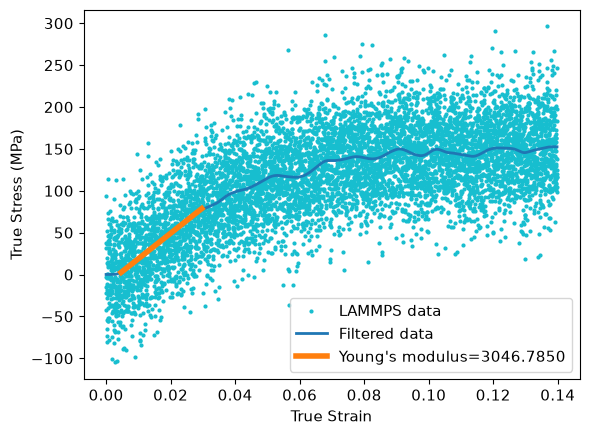

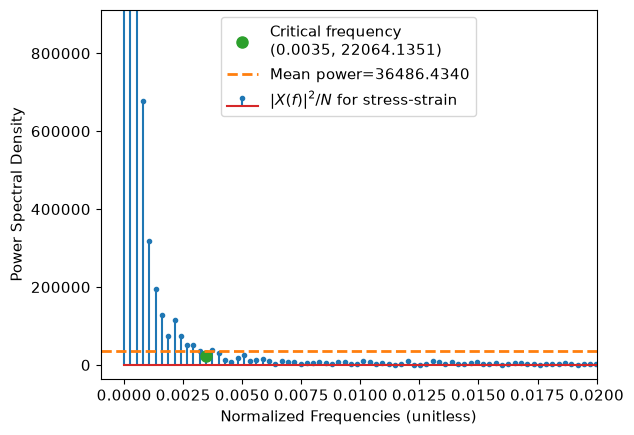

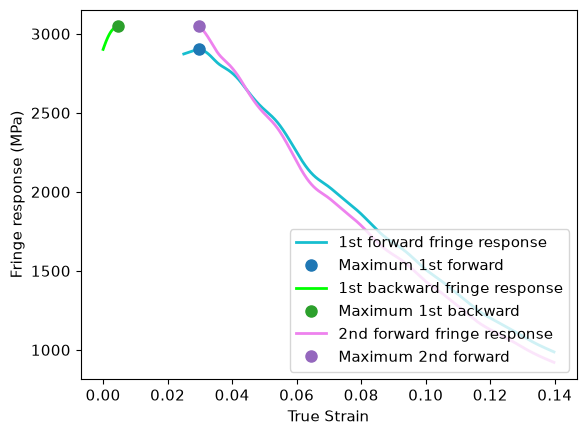

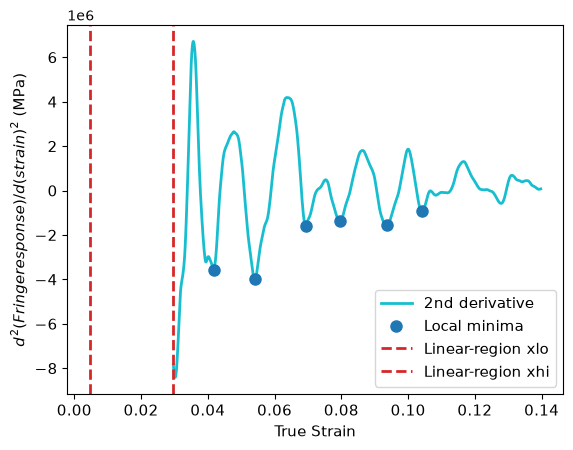

In [8]:
fs = 11 # Set fontsize
plt.plot(strain, stress, '.', ms=4, color='tab:cyan', label='LAMMPS data')
plt.plot(strain, filtered_stress, '-', lw=2, color='tab:blue', label='Filtered data')
plt.plot(youngs_modulus_x, youngs_modulus_y, '-', lw=4, color='tab:orange', label="Young's modulus={:.4f}".format(youngs_modulus_coeffs[1]))
plt.legend(loc='lower right', bbox_to_anchor=(1, 0), fancybox=True, ncol=1, fontsize=fs)
plt.xlabel('True Strain', fontsize=fs)
plt.ylabel('True Stress (MPa)', fontsize=fs)
plt.tick_params(axis='both', which='major', labelsize=fs)
plt.show()

if str(wn).startswith('op'):
    plt.stem(wns_stress, psd_stress, linefmt='tab:blue', markerfmt='.', label='$|X(f)|^2/N$ for stress-strain')
    plt.plot(wn_stress, power_stress, 'o', ms=8, color='tab:green', label='Critical frequency\n({:.4f}, {:.4f})'.format(wn_stress, power_stress))
    plt.axhline(mean_stress_psd, color='tab:orange', ls='--', lw=2, label='Mean power={:.4f}'.format(mean_stress_psd))
    plt.xlabel('Normalized Frequencies (unitless)', fontsize=fs)
    plt.ylabel('Power Spectral Density', fontsize=fs)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.0), fancybox=True, ncol=1, fontsize=fs)
    plt.tick_params(axis='both', which='major', labelsize=fs)
    plt.xlim((-0.001, 0.02)) # Comment/uncomment for xlimits
    plt.ylim((-1*mean_stress_psd, 25*mean_stress_psd)) # Comment/uncomment for xlimits
    plt.show()

plt.plot(fr1_fringe, fr1_slopes, '-', lw=2, color='tab:cyan', label='1st forward fringe response')
plt.plot(fr1_max_fringe, fr1_max_slope, 'o', ms=8, color='tab:blue', label='Maximum 1st forward')
plt.plot(br1_fringe, br1_slopes, '-', lw=2, color='lime', label='1st backward fringe response')
plt.plot(br1_max_fringe, br1_max_slope, 'o', ms=8, color='tab:green', label='Maximum 1st backward')
plt.plot(fr2_fringe, fr2_slopes, '-', lw=2, color='violet', label='2nd forward fringe response')
plt.plot(fr2_max_fringe, fr2_max_slope, 'o', ms=8, color='tab:purple', label='Maximum 2nd forward')
plt.legend(loc='lower right', bbox_to_anchor=(1, 0), fancybox=True, ncol=1, fontsize=fs)
plt.xlabel('True Strain', fontsize=fs)
plt.ylabel('Fringe response (MPa)', fontsize=fs)
plt.tick_params(axis='both', which='major', labelsize=fs)
plt.show()

plt.plot(dstrain, dslopes2, '-', lw=2,  color='tab:cyan', label='2nd derivative')
plt.plot(xvalleys, yvalleys, 'o', ms=8, color='tab:blue', label='Local minima')
plt.axvline(xlo, color='tab:red', ls='--', lw=2, label='Linear-region xlo')
plt.axvline(xhi, color='tab:red', ls='--', lw=2, label='Linear-region xhi')
plt.legend(loc='lower right', bbox_to_anchor=(1, 0), fancybox=True, ncol=1, fontsize=fs)
plt.xlabel('True Strain', fontsize=fs)
plt.ylabel('$d^2(Fringe response)/d(strain)^2$ (MPa)', fontsize=fs)
plt.tick_params(axis='both', which='major', labelsize=fs)
plt.show()